In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

In [2]:
cancer = load_breast_cancer()

X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="diagnosis")

print("Dataset shape:", X.shape)
print("Target classes:", cancer.target_names)
display(X.head())

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Feature names:")
print(X.columns.tolist())

print("\\nClass distribution:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

print("\\nMissing values:", X.isnull().sum().sum())
print("\\nDataset description:")
print(cancer.DESCR[:1200])

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
\nClass distribution:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64
\nMissing values: 0
\nDataset description:
.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
 

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 455
Testing records: 114


In [5]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [6]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.map({0: "malignant", 1: "benign"}).values,
    "Predicted": pd.Series(y_pred).map({0: "malignant", 1: "benign"}).values
})

display(comparison.head(10))

,Actual,Predicted
0,malignant,malignant
1,benign,benign
2,malignant,malignant
3,benign,benign
4,malignant,malignant
5,benign,benign
6,benign,benign
7,malignant,malignant
8,malignant,malignant
9,malignant,malignant


In [7]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=cancer.target_names,
    zero_division=0
))

Accuracy: 0.9386
\nClassification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



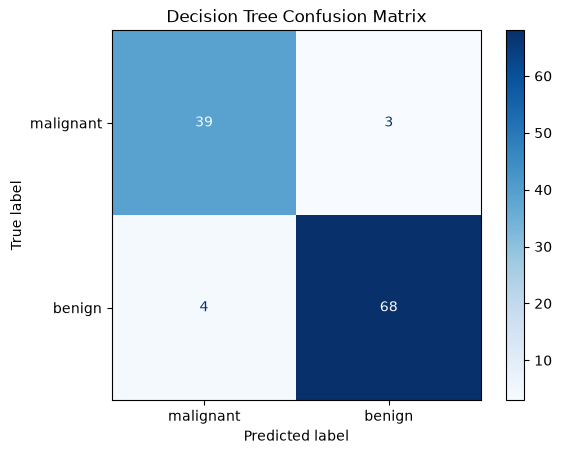

In [12]:
cm = confusion_matrix(y_test, y_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cancer.target_names
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Decision Tree Confusion Matrix")
plt.show()

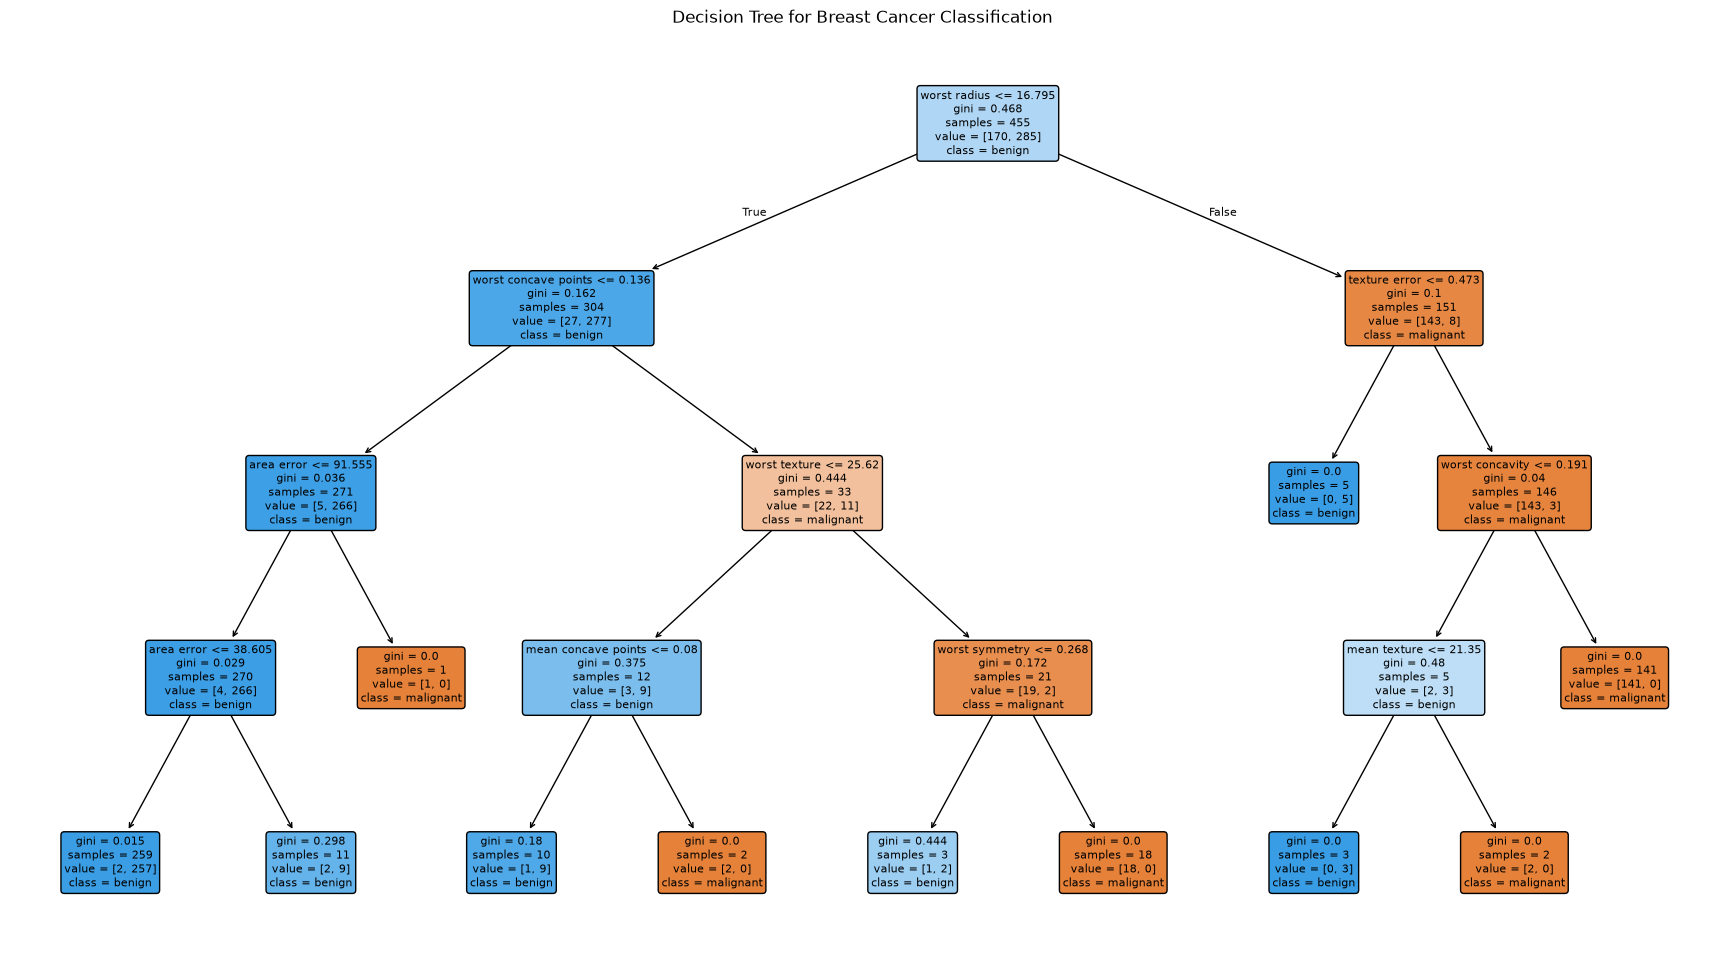

In [13]:
plt.figure(figsize=(22, 12))
plot_tree(
    model,
    feature_names=cancer.feature_names,
    class_names=cancer.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree for Breast Cancer Classification")
plt.show()

In [16]:
del display
from IPython.display import display

,Feature,Importance
20,worst radius,0.733548
27,worst concave points,0.122028
11,texture error,0.045785
21,worst texture,0.032319
26,worst concavity,0.017161
7,mean concave points,0.013327
13,area error,0.012704
1,mean texture,0.011846
28,worst symmetry,0.011282
3,mean area,0.000000


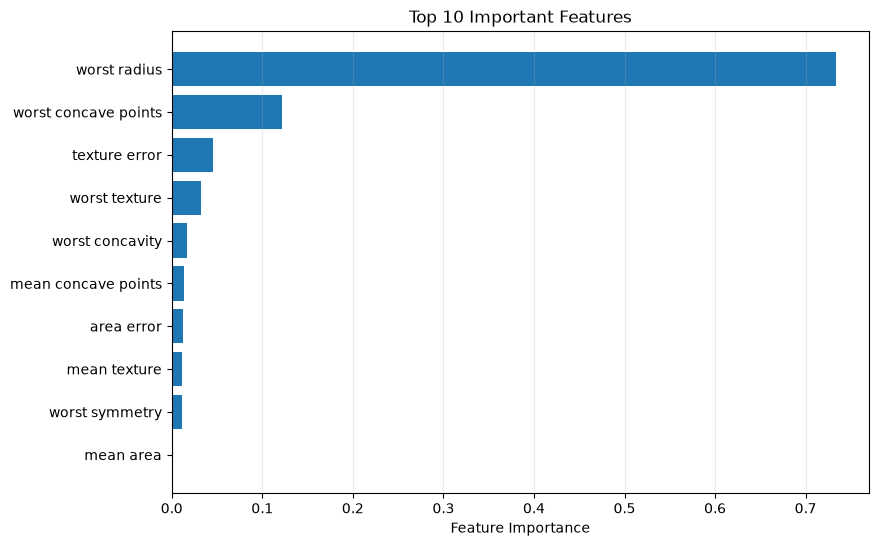

In [17]:
importance = pd.DataFrame({
    "Feature": cancer.feature_names,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(10))

top_features = importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features")
plt.grid(axis="x", alpha=0.25)
plt.show()

In [18]:
sample = X_test.iloc[[0]]
actual_class = y_test.iloc[0]
predicted_class = model.predict(sample)[0]

print("Predicted diagnosis:", cancer.target_names[predicted_class])
print("Actual diagnosis:", cancer.target_names[actual_class])

Predicted diagnosis: malignant
Actual diagnosis: malignant
